# NIR 醋酸最佳光徑選擇：程式練習

**目標**：用一組真實的 NeoSpectra 近紅外光譜（水 + 三瓶醋，光徑 0.25 / 0.5 / 1 / 2 / 5 mm），
自己一步一步判斷「該選哪個光徑」，並把過程中用到的四個統計基礎各**手刻一次**：

| 基礎 | 內容 |
|---|---|
| ① | Beer–Lambert 定律與儀器飽和 |
| ② | 二階導數與 Savitzky–Golay (SG) 濾波器 |
| ③ | 線性迴歸（斜率、截距、R²） |
| ④ | 偵測極限 LOD = 3σ / \|斜率\| |
| ⑤ | 留一交叉驗證 (LOOCV) 與 RMSECV |

**每一節的節奏**：先用幾個數字的小例子弄懂 → 自己用公式手刻 → 套到真實資料 → 用現成套件對照。
只使用 numpy、pandas、matplotlib、scipy（scipy 只用來「對照」，檢查你手刻的結果有沒有對）。

**資料欄位**（`spectra_long.csv`）：`path_mm`（光徑）、`sample`、`label_pct`（瓶身標示 %）、
`acid_pct`（Atago 酸度計實測 %，0 / 3.32 / 4.87 / 7.45）、`replicate`、`wavelength_nm`、`absorbance`。
共 21 條光譜 × 142 個波長。0.25 mm 的水另有 `replicate = 2` 的重複量測，主分析只用 `replicate == 1`。

**注意**：圖上的文字一律用英文，因為 Colab 沒有中文字型，中文會變成方塊；說明文字都放在這些 markdown 格子裡。

> **Google Colab 版**
>
> **如何在 Colab 開啟**：
> 1. 開啟 [colab.research.google.com](https://colab.research.google.com)。
> 2. 選單「**檔案 → 上傳筆記本**」，選擇 `pathlength_exercise_colab.ipynb`。
> 3. 依序執行每一格（「執行階段 → 全部執行」也可以）。
>
> Colab 看不到你電腦上的檔案，所以下一格會把資料**內嵌**在筆記本裡並自動解出 `spectra_long.csv`，不用另外上傳。
> Colab 已內建 numpy、pandas、matplotlib、scipy，不需安裝任何套件。

In [1]:
# 資料內嵌：把 spectra_long.csv 以 gzip + base64 存成字串，執行時解出成檔案
import base64, gzip
DATA_B64 = """
...
"""
with open('spectra_long.csv', 'wb') as _f:
    _f.write(gzip.decompress(base64.b64decode(DATA_B64)))
DATA_PATH = 'spectra_long.csv'
print('已解出 spectra_long.csv：', len(gzip.decompress(base64.b64decode(DATA_B64))), 'bytes')

已解出 spectra_long.csv： 127618 bytes


若想改用自己上傳的檔案，可執行下面這一格（可選；不執行也不影響後面的練習）。

In [2]:
# 【可選】如果你想改用自己上傳的 spectra_long.csv，執行這一格並選擇檔案。
# 不在 Colab 時（例如本機）會自動略過，不會報錯。
try:
    from google.colab import files
    _up = files.upload()          # 跳出選檔視窗；不想上傳就直接按取消
    if 'spectra_long.csv' in _up:
        DATA_PATH = 'spectra_long.csv'
        print('已改用你上傳的 spectra_long.csv')
    else:
        print('沒有上傳 spectra_long.csv，繼續使用內嵌資料')
except Exception as _e:
    print('略過上傳（非 Colab 環境或未選檔）：', type(_e).__name__)

略過上傳（非 Colab 環境或未選檔）： ModuleNotFoundError


## 0. 載入資料、畫出 5 個光徑的光譜

先把資料整理成「每個光徑一個 4 × 142 的矩陣」：4 列依序是水 (0%)、3.32%、4.87%、7.45%，142 欄是波長。
之後所有計算都以這個 `spec[光徑]` 為基礎。

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, savgol_coeffs   # 只用來「對照」手刻結果

np.set_printoptions(precision=5, linewidth=130)
plt.rcParams['figure.dpi'] = 90

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(2982, 7)


,path_mm,sample,label_pct,acid_pct,replicate,wavelength_nm,absorbance
0,0.25,water,0.0,0.0,1,1346.911,0.406408
1,0.25,water,0.0,0.0,1,1351.418,0.407583
2,0.25,water,0.0,0.0,1,1355.955,0.408562
3,0.25,water,0.0,0.0,1,1360.522,0.409016
4,0.25,water,0.0,0.0,1,1365.121,0.410542


In [4]:
# ---- 可調整的參數（練習題會請你改這幾個值）----
A_LIM      = 1.5     # 保守的線性吸光度上限
A_SAT      = 2.0     # 飽和判斷值
SG_WIN     = 9       # 二階導數的 SG 視窗點數（奇數）
SMOOTH_WIN = 7       # 估計雜訊用的 SG 平滑視窗
RATIO_TOL  = 0.2     # 第 7 節：靈敏度比與理想值的容許偏差（20%）
BANDS = {'2258': 2258, '1670': 1670}   # 醋酸特徵帶 (nm)：C-H 組合帶、C-H 一倍頻

PATHS = [0.25, 0.5, 1, 2, 5]
ACID  = [0, 3.32, 4.87, 7.45]          # Atago 實測酸度 (%)
LABEL = ['water 0%', '3.32%', '4.87%', '7.45%']
COLORS = ['k', 'tab:blue', 'tab:green', 'tab:red']

波長範圍 1346.9 - 2542.3 nm, 共 142 點
spec[1].shape = (4, 142)


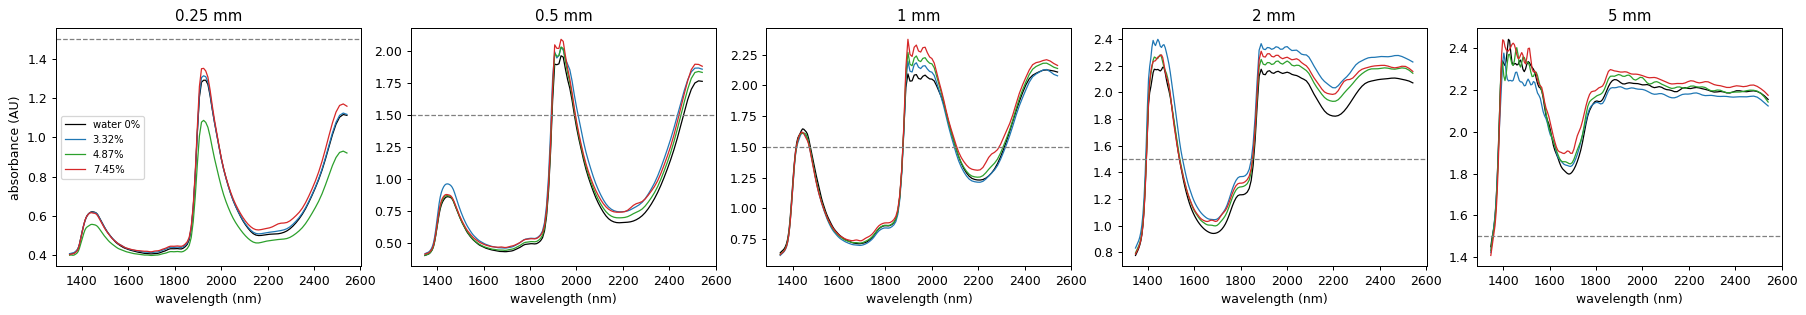

In [5]:
main = df[df.replicate == 1]
wl = np.sort(main.wavelength_nm.unique())
n_wl = len(wl)

spec = {}                                  # spec[光徑] -> 4 x 142 的吸光度矩陣
for p in PATHS:
    rows = []
    for a in ACID:
        h = main[(main.path_mm == p) & np.isclose(main.acid_pct, a)].sort_values('wavelength_nm')
        assert len(h) == n_wl and np.allclose(h.wavelength_nm.values, wl)
        rows.append(h.absorbance.values)
    spec[p] = np.array(rows)

print('波長範圍 %.1f - %.1f nm, 共 %d 點' % (wl[0], wl[-1], n_wl))
print('spec[1].shape =', spec[1].shape)

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=False)
for ax, p in zip(axes, PATHS):
    for i in range(4):
        ax.plot(wl, spec[p][i], COLORS[i], lw=1, label=LABEL[i])
    ax.axhline(1.5, color='gray', ls='--', lw=1)
    ax.set_title('%g mm' % p)
    ax.set_xlabel('wavelength (nm)')
axes[0].set_ylabel('absorbance (AU)')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**觀察**：虛線是 A = 1.5。光徑越長，整條光譜越高；2 mm 與 5 mm 的高處被「削平」（平台），那就是儀器的吸光度上限。

### 動手改改看（第 0 節）
1. 把 `ACID` 的第二個值 3.32 改成 3.0（標示值），哪些地方會報錯？為什麼 `np.isclose` 比較時要小心？
2. 只畫 `spec[1]` 的 7.45% 那條，把 x 軸範圍限制在 2100–2300 nm，看看 2258 nm 附近的吸收帶長什麼樣子。

## 1. 基礎①：Beer–Lambert 與飽和

**Beer–Lambert 定律**：A = ε · b · c
（A 吸光度、ε 莫耳吸收係數、b 光徑、c 濃度）。在 ε 與 c 固定時，**吸光度應正比於光徑**。

但儀器偵測器有極限：吸光度太高時，穿透光太弱，讀值就不再增加，出現**平台**（本資料約在 A ≈ 2.2–2.4）。
進入平台後 A 不再正比於光徑與濃度，Beer–Lambert 失效。

先用一個玩具例子感受：假設某樣品每 mm 吸 2.0 AU，儀器上限 2.3 AU。

In [6]:
# 玩具例子：理想吸光度 vs. 有上限的儀器讀值
b = np.array(PATHS, dtype=float)
eps_c = 2.0                       # 假想的 epsilon*c，單位 AU/mm
A_true = eps_c * b                # 理想：正比於光徑
A_obs = np.minimum(A_true, 2.3)   # 儀器：超過 2.3 就削平
print(pd.DataFrame({'path_mm': b, 'A_true': A_true, 'A_obs': A_obs}).to_string(index=False))

 path_mm  A_true  A_obs
    0.25     0.5    0.5
    0.50     1.0    1.0
    1.00     2.0    2.0
    2.00     4.0    2.3
    5.00    10.0    2.3


 path_mm  max_A  frac_A<1.5  frac_A<2
    0.25 1.3521      1.0000    1.0000
    0.50 2.0928      0.8662    0.9648
    1.00 2.3743      0.6197    0.8099
    2.00 2.3977      0.3662    0.4437
    5.00 2.4434      0.0141    0.1690


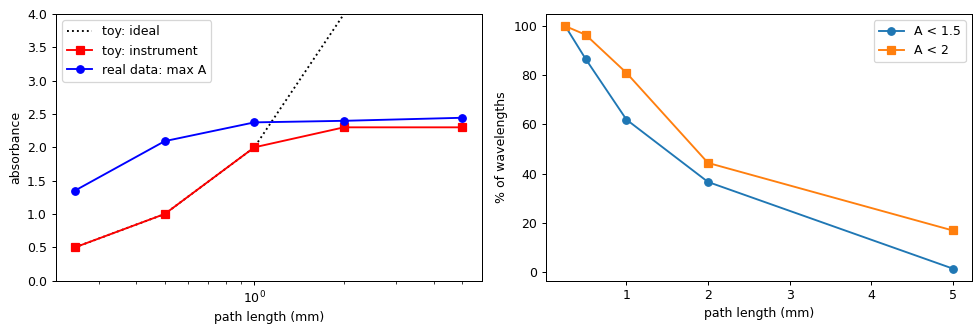

In [7]:
# 真實資料：各光徑 4 條光譜「全部」低於門檻的波長比例
def frac_below(S, thr):
    # S: 4 x 142。某波長要算「未飽和」，4 條光譜在該波長都要 < thr
    return float(np.mean(S.max(axis=0) < thr))

tab1 = pd.DataFrame({
    'path_mm': PATHS,
    'max_A':   [spec[p].max() for p in PATHS],
    'frac_A<%g' % A_LIM: [frac_below(spec[p], A_LIM) for p in PATHS],
    'frac_A<%g' % A_SAT: [frac_below(spec[p], A_SAT) for p in PATHS],
})
print(tab1.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(PATHS, A_true[:len(PATHS)], 'k:', label='toy: ideal')
ax[0].semilogx(PATHS, A_obs[:len(PATHS)], 'rs-', label='toy: instrument')
ax[0].semilogx(PATHS, [spec[p].max() for p in PATHS], 'bo-', label='real data: max A')
ax[0].set_xlabel('path length (mm)'); ax[0].set_ylabel('absorbance'); ax[0].set_ylim(0, 4); ax[0].legend()
ax[1].plot(PATHS, [100 * frac_below(spec[p], A_LIM) for p in PATHS], 'o-', label='A < %g' % A_LIM)
ax[1].plot(PATHS, [100 * frac_below(spec[p], A_SAT) for p in PATHS], 's-', label='A < %g' % A_SAT)
ax[1].set_xlabel('path length (mm)'); ax[1].set_ylabel('% of wavelengths'); ax[1].legend()
plt.tight_layout(); plt.show()

**讀表**：0.25 mm 全部波長都未飽和；到 5 mm 只剩約 1.4% 的波長 A < 1.5。
所以「光徑越長越好」不成立：光徑長 → 靈敏度高，但太長會進入飽和。接下來要找的是**兩者的平衡點**。

### 動手改改看（第 1 節）
1. 把 `A_LIM` 改成 2.0（上面參數格），重跑第 1 節。哪個光徑的比例變化最大？為什麼？
2. 玩具例子中把儀器上限改成 1.5，哪幾個光徑會被削平？
3. 為什麼要求「4 條光譜在該波長都 < 門檻」，而不是只看 7.45% 那一條？

## 2. 基礎②：二階導數與 Savitzky–Golay

### 2.1 為什麼用二階導數？
NIR 光譜常有**基線偏移**（整條光譜平移）與**基線斜率**（整條光譜傾斜），多半來自填樣方式不同。
一階導數會消除常數偏移；**二階導數同時消除常數偏移與線性斜率**，只留下「曲率」，也就是吸收帶的形狀。

玩具例子：y = a·x² 加上常數偏移與斜率。用**有限差分**求二階導數（點間距 = 1）：

d²y ≈ y[i−1] − 2·y[i] + y[i+1]

數學上，對 a·x² 這個差分結果會剛好等於 2a。

plain          前 3 個二階導數 = [0.04 0.04 0.04]
+offset        前 3 個二階導數 = [0.04 0.04 0.04]
+offset+slope  前 3 個二階導數 = [0.04 0.04 0.04]
理論值 2a = 0.04


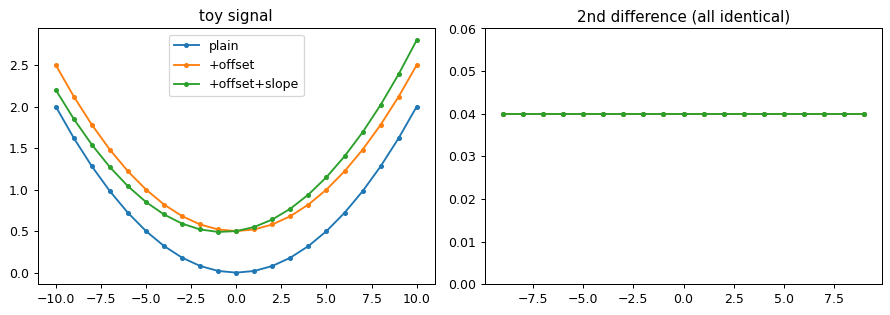

In [8]:
x = np.arange(-10, 11)
a_true = 0.02
y_plain   = a_true * x**2                       # 只有曲率
y_offset  = a_true * x**2 + 0.5                 # 加常數偏移
y_tilt    = a_true * x**2 + 0.5 + 0.03 * x      # 再加斜率

def fd2(y):
    # 有限差分二階導數：y[i-1] - 2*y[i] + y[i+1]，頭尾各少一點
    return y[:-2] - 2 * y[1:-1] + y[2:]

for name, y in [('plain', y_plain), ('+offset', y_offset), ('+offset+slope', y_tilt)]:
    print('%-14s 前 3 個二階導數 = %s' % (name, np.round(fd2(y)[:3], 6)))
print('理論值 2a =', 2 * a_true)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for name, y in [('plain', y_plain), ('+offset', y_offset), ('+offset+slope', y_tilt)]:
    ax[0].plot(x, y, 'o-', ms=3, label=name)
    ax[1].plot(x[1:-1], fd2(y), 'o-', ms=3, label=name)
ax[0].set_title('toy signal'); ax[1].set_title('2nd difference (all identical)')
ax[0].legend(); ax[1].set_ylim(0, 0.06)
plt.tight_layout(); plt.show()

三條曲線形狀差很多，但二階導數**完全相同**：偏移與斜率都被消掉了。

### 2.2 有雜訊怎麼辦？Savitzky–Golay = 視窗內擬合二次多項式
有限差分會放大雜訊。**Savitzky–Golay (SG)** 的想法：
對每個點，取它前後共 9 點（視窗 9），用**最小平方法擬合一個二次多項式** y ≈ a₀ + a₁·x + a₂·x²
（x = −4…+4 是視窗內的索引），那麼在視窗中心：

- 平滑值 = a₀
- 一階導數 = a₁
- **二階導數 = 2·a₂**

最小平方的解是線性的，所以「2·a₂」其實等於視窗內 9 個點乘上一組固定係數再加總（卷積係數 c2）。
先用玩具資料驗證「擬合二次式取 2a₂」與「係數相乘」是同一件事：

In [9]:
rng = np.random.default_rng(0)
y_noisy = y_tilt + rng.normal(0, 0.002, size=y_tilt.size)   # 加一點雜訊

w = 9; h = w // 2
xs = np.arange(-h, h + 1)                    # 視窗內的索引 -4..4（點間距 = 1）
center = 10                                  # 取第 10 點為中心
seg = y_noisy[center - h: center + h + 1]

a2, a1, a0 = np.polyfit(xs, seg, 2)          # 擬合二次式
print('方法 A：擬合二次式，二階導數 = 2*a2 = %.6f' % (2 * a2))

def sg_coeffs(window, deriv):
    # 手刻 SG 係數：設計矩陣 X = [1, x, x^2]，最小平方解 = pinv(X) @ y
    hh = window // 2
    xx = np.arange(-hh, hh + 1)
    X = np.vander(xx, 3, increasing=True)    # 三個欄位：1, x, x^2
    P = np.linalg.pinv(X)                    # 3 x window；第 k 列 = 係數 a_k 的權重
    if deriv == 0:
        return P[0]                          # 平滑：a0
    if deriv == 2:
        return 2 * P[2]                      # 二階導數：2*a2
    raise ValueError('只實作 deriv = 0 或 2')

c2 = sg_coeffs(9, 2)
print('9 點二次二階導數係數 c2 =', np.round(c2, 5))
print('方法 B：c2 與視窗 9 點相乘加總 = %.6f' % np.dot(c2, seg))
print('與 scipy 係數最大差異 = %.2e' % np.abs(c2 - savgol_coeffs(9, 2, deriv=2)).max())

方法 A：擬合二次式，二階導數 = 2*a2 = 0.040278
9 點二次二階導數係數 c2 = [ 0.06061  0.01515 -0.01732 -0.0368  -0.04329 -0.0368  -0.01732  0.01515  0.06061]
方法 B：c2 與視窗 9 點相乘加總 = 0.040278
與 scipy 係數最大差異 = 2.95e-17


兩種方法結果一樣。**c2 的特徵**：中間為負、兩側為正、總和為 0（所以常數偏移被消掉）；
而且係數加權後 Σ c2·x = 0（所以線性斜率也被消掉）。

### 2.3 套到整條光譜（手刻 SG）
**慣例（與 scipy 的 `savgol_filter(S, 9, 2, deriv=2)` 相同）**：視窗以「索引」為單位、點間距 = 1。

> **單位陷阱**：本資料的波長網格**不等距**（間距約 4.5–15.9 nm），所以這裡算出來的 d²A/dλ²，
> 其實是「每點²」(per index²) 的二階導數，不是真正的「每 nm²」。
> 整份分析（以及原報告）都用同一個索引單位，因此比較不同光徑時沒問題，
> 但數值不能直接當成物理上的 AU/nm²。

In [10]:
def sg_apply(S, coef):
    # 把係數套到每一列光譜；視窗不足的頭尾幾點給 NaN（scipy 預設會用邊界擬合，這裡不處理）
    half = len(coef) // 2
    out = np.full(S.shape, np.nan)
    for i in range(half, S.shape[1] - half):
        out[:, i] = S[:, i - half: i + half + 1] @ coef
    return out

c2 = sg_coeffs(SG_WIN, 2)
print('波長間距 (nm)：最小 %.2f，最大 %.2f（不等距）' % (np.diff(wl).min(), np.diff(wl).max()))

D2 = {p: sg_apply(spec[p], c2) for p in PATHS}      # 手刻結果

# 與 scipy 對照（只比較內部點）
maxdiff = 0
for p in PATHS:
    ref = savgol_filter(spec[p], SG_WIN, 2, deriv=2, axis=1)
    half = SG_WIN // 2
    maxdiff = max(maxdiff, np.abs(D2[p][:, half:-half] - ref[:, half:-half]).max())
print('手刻 SG 與 scipy savgol_filter 的最大差異 = %.2e' % maxdiff)

波長間距 (nm)：最小 4.51，最大 15.90（不等距）
手刻 SG 與 scipy savgol_filter 的最大差異 = 5.01e-16


特徵帶 2258 nm -> 索引 121 (實際波長 2258.07 nm)
特徵帶 1670 nm -> 索引 58 (實際波長 1669.90 nm)


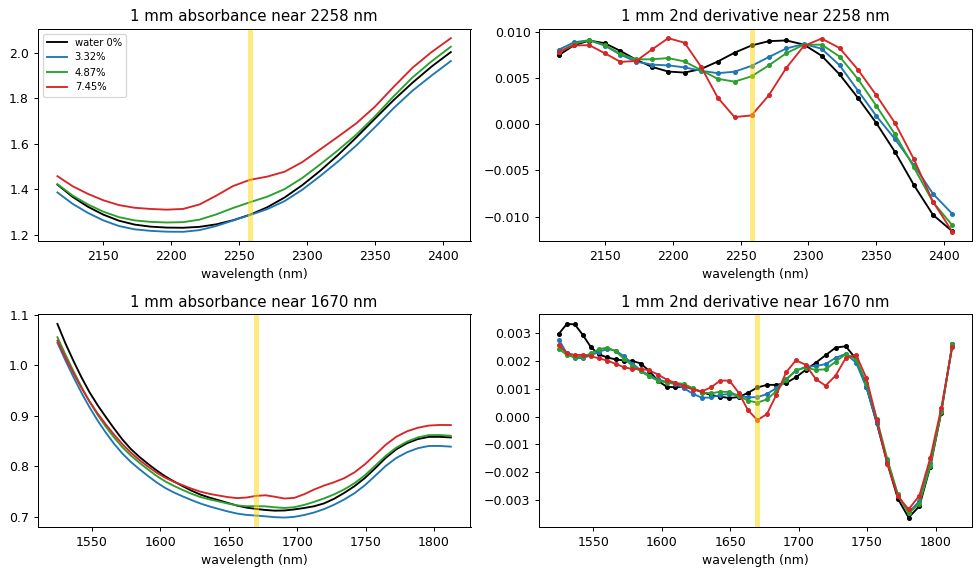

1 mm 在 2258 nm 帶的二階導數值（水, 3.32, 4.87, 7.45）： [0.00851 0.00631 0.00517 0.00095]


In [11]:
def band_index(w0):
    return int(np.argmin(np.abs(wl - w0)))     # 最接近 w0 的那一個波長點

IDX = {k: band_index(v) for k, v in BANDS.items()}
for k, i in IDX.items():
    print('特徵帶 %s nm -> 索引 %d (實際波長 %.2f nm)' % (k, i, wl[i]))

fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
for r, k in enumerate(BANDS):
    i = IDX[k]
    m = (wl > wl[i] - 150) & (wl < wl[i] + 150)
    for j in range(4):
        ax[r, 0].plot(wl[m], spec[1][j][m], COLORS[j], label=LABEL[j])
        ax[r, 1].plot(wl[m], D2[1][j][m], '.-', color=COLORS[j], label=LABEL[j])
    for c in (0, 1):
        ax[r, c].axvline(wl[i], color='gold', lw=4, alpha=0.5)
        ax[r, c].set_xlabel('wavelength (nm)')
    ax[r, 0].set_title('1 mm absorbance near %s nm' % k)
    ax[r, 1].set_title('1 mm 2nd derivative near %s nm' % k)
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print('1 mm 在 2258 nm 帶的二階導數值（水, 3.32, 4.87, 7.45）：', np.round(D2[1][:, IDX['2258']], 6))

**觀察**：吸收帶中心 (2258 nm) 的二階導數是負的（吸收峰的曲率向下），酸度越高越負。
這個數字就是下一節回歸用的 y。

### 動手改改看（第 2 節）
1. 把 `SG_WIN` 改成 15，重跑第 2 節以後的所有格子（參數格要先重跑）。二階導數曲線變得更平滑還是更雜？
   `c2` 係數長什麼樣？最後的自我驗證有些項目會 FAIL，這是正常的，想想為什麼。
2. 玩具例子把 `y_tilt` 再加上 0.01·x³（三次項），二階導數還會相同嗎？
3. 為什麼 SG 視窗比有限差分「抗雜訊」？（提示：比較 `np.sum(c2**2)` 與有限差分係數 [1, −2, 1] 的 Σ平方 = 6）

## 3. 基礎③：線性迴歸

校正線：y = 截距 + 斜率 · x。這裡 **x = acid_pct（水 = 0 加三瓶醋，n = 4）**，
**y = 該特徵帶的二階導數值**。最小平方公式：

- 斜率 = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²
- 截距 = ȳ − 斜率 · x̄
- R² = 1 − SS_res / SS_tot，其中 SS_res = Σ(y − ŷ)²，SS_tot = Σ(y − ȳ)²

先用 4 個點的玩具例子手算：

In [12]:
def fit_line(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    sxx = np.sum((x - x.mean())**2)
    sxy = np.sum((x - x.mean()) * (y - y.mean()))
    slope = sxy / sxx
    intercept = y.mean() - slope * x.mean()
    pred = intercept + slope * x
    r2 = 1 - np.sum((y - pred)**2) / np.sum((y - y.mean())**2)
    return slope, intercept, r2

xt = np.array([1, 2, 3, 4.]); yt = np.array([2.1, 3.9, 6.2, 7.8])
s, b0, r2 = fit_line(xt, yt)
print('手刻：斜率 %.4f 截距 %.4f R2 %.4f' % (s, b0, r2))
ps, pb = np.polyfit(xt, yt, 1)
print('np.polyfit：斜率 %.4f 截距 %.4f' % (ps, pb))

手刻：斜率 1.9400 截距 0.1500 R2 0.9957
np.polyfit：斜率 1.9400 截距 0.1500


 path_mm band_nm      slope  intercept     R2
    0.25    2258 -0.0002497    0.00207 0.9589
     0.5    2258 -0.0004812   0.004662 0.8533
       1    2258 -0.0009852   0.009087 0.9342
       2    2258 -0.0008427   0.004378 0.9498
       5    2258  8.893e-05 -0.0008745  0.323
    0.25    1670 -2.859e-05  0.0001994 0.8548
     0.5    1670 -7.549e-05  0.0005429 0.7873
       1    1670 -0.0001535    0.00113 0.9448
       2    1670  -0.000301   0.002214 0.8508
       5    1670 -0.0004342    0.00305  0.999

1 mm / 2258 nm：手刻斜率 -9.851954e-04，np.polyfit 斜率 -9.851954e-04


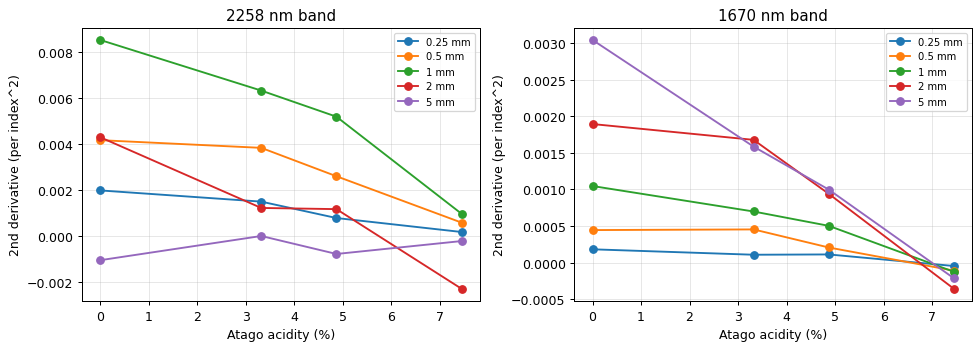

In [13]:
# 套到真實資料：每個光徑 x 每個特徵帶
conc = np.array(ACID, float)
CAL = {}
for p in PATHS:
    for k in BANDS:
        sig = D2[p][:, IDX[k]]                  # 4 個二階導數值（水, 3.32, 4.87, 7.45）
        s, b0, r2 = fit_line(conc, sig)
        CAL[(p, k)] = dict(sig=sig, slope=s, intercept=b0, r2=r2)

tab3 = pd.DataFrame([{'path_mm': p, 'band_nm': k, 'slope': CAL[(p, k)]['slope'],
                      'intercept': CAL[(p, k)]['intercept'], 'R2': CAL[(p, k)]['r2']}
                     for k in BANDS for p in PATHS])
print(tab3.to_string(index=False, float_format=lambda v: '%.4g' % v))

# 與 np.polyfit 對照（1 mm, 2258 nm）
s_np, b_np = np.polyfit(conc, CAL[(1, '2258')]['sig'], 1)
print('\n1 mm / 2258 nm：手刻斜率 %.6e，np.polyfit 斜率 %.6e' % (CAL[(1, '2258')]['slope'], s_np))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, k in enumerate(BANDS):
    for p in PATHS:
        ax[c].plot(conc, CAL[(p, k)]['sig'], 'o-', label='%g mm' % p)
    ax[c].set_xlabel('Atago acidity (%)'); ax[c].set_ylabel('2nd derivative (per index^2)')
    ax[c].set_title('%s nm band' % k); ax[c].legend(fontsize=8); ax[c].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**注意**：n = 4 的 R² 很容易「偶然偏高」（例如已飽和的 2 mm，R² 反而有 0.95）。
**R² 不能單獨當作選光徑的依據**，這就是下一節要檢查 Beer–Lambert 的原因。

### 動手改改看（第 3 節）
1. 刪掉 0.25 mm 的 4.87% 那條光譜（也就是把 `conc` 與 `sig` 各拿掉第 3 個元素，只剩 n = 3），0.25 mm 的斜率與 R² 會怎麼變？
   報告說這條光譜疑似整體縮小約 15%，你的結果支持嗎？
2. 把 x 改成「標示值」[0, 3, 5, 10]，1 mm 的 R² 是否更高？（第 8 節會正式做。）
3. 為什麼回歸只有 4 個點時，R² 接近 1 並不代表模型好？

## 4. Beer–Lambert 正比檢查

二階導數的訊號也正比於吸光度，所以**靈敏度（斜率）應該正比於光徑**：

靈敏度比 = slope(p) / slope(0.25 mm)，理想值 = p / 0.25
（0.5 mm → 2、1 mm → 4、2 mm → 8、5 mm → 20）。實際值若明顯低於理想值，就表示已進入飽和。

band_nm  path_mm  ratio  ideal  ratio/ideal
   2258    0.250  1.000  1.000        1.000
   2258    0.500  1.927  2.000        0.964
   2258    1.000  3.946  4.000        0.987
   2258    2.000  3.375  8.000        0.422
   2258    5.000 -0.356 20.000       -0.018
   1670    0.250  1.000  1.000        1.000
   1670    0.500  2.640  2.000        1.320
   1670    1.000  5.369  4.000        1.342
   1670    2.000 10.528  8.000        1.316
   1670    5.000 15.186 20.000        0.759


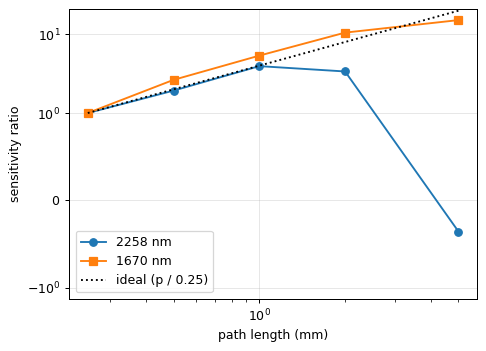

In [14]:
ratio_tab = []
for k in BANDS:
    base = CAL[(0.25, k)]['slope']
    for p in PATHS:
        ratio = CAL[(p, k)]['slope'] / base
        ratio_tab.append({'band_nm': k, 'path_mm': p, 'ratio': ratio, 'ideal': p / 0.25,
                          'ratio/ideal': ratio / (p / 0.25)})
print(pd.DataFrame(ratio_tab).to_string(index=False, float_format=lambda v: '%.3f' % v))

fig, ax = plt.subplots(figsize=(5.5, 4))
for k, mk in zip(BANDS, ['o-', 's-']):
    ax.plot(PATHS, [CAL[(p, k)]['slope'] / CAL[(0.25, k)]['slope'] for p in PATHS], mk, label='%s nm' % k)
ax.plot(PATHS, [p / 0.25 for p in PATHS], 'k:', label='ideal (p / 0.25)')
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('path length (mm)'); ax.set_ylabel('sensitivity ratio'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**2258 nm 帶的比值**：0.25 → 0.5 → 1 mm 為 1 : 1.93 : 3.95，非常接近理想的 1 : 2 : 4；
到 2 mm 只有 3.38（理想 8），5 mm 甚至是負的，表示 2 mm 以上已飽和。
1670 nm 帶的比值本來就比較亂（訊號弱，0.25 mm 的斜率很小，分母不穩），主要依 2258 nm 判斷。

### 動手改改看（第 4 節）
1. 若以 0.5 mm 當基準（slope(p)/slope(0.5)），理想值要怎麼改？結論會一樣嗎？
2. 為什麼 5 mm 的比值會是負的？（提示：回到第 0 節的圖，看 2258 nm 附近的光譜形狀。）

## 5. 基礎④：偵測極限 LOD = 3σ / |斜率|

LOD（limit of detection）的意思：訊號要超過雜訊的 3 倍，才能說「有偵測到」。
折算成濃度：**LOD = 3σ / |斜率|**，σ 是**訊號（這裡是二階導數）的雜訊標準差**，斜率是校正線斜率（訊號/% 酸度）。
斜率越大、雜訊越小，LOD 越低。

### 5.1 雜訊怎麼傳遞到二階導數？
二階導數 = Σ c2ᵢ · yᵢ。如果每個 yᵢ 都有獨立、標準差 σA 的雜訊，
則二階導數的雜訊標準差 = **σA · √(Σ c2ᵢ²)**。用模擬驗證：

In [15]:
rng = np.random.default_rng(1)
sigmaA = 1.0
noise = rng.normal(0, sigmaA, size=200000)
# 對純雜訊序列套用 c2，再算標準差
d2_noise = np.convolve(noise, c2, mode='valid')
print('模擬：二階導數雜訊 std = %.4f' % d2_noise.std())
print('公式：sigma_A * sqrt(sum(c2^2)) = %.4f' % (sigmaA * np.sqrt(np.sum(c2**2))))
print('對照：有限差分 [1,-2,1] 的放大倍率 = %.4f' % np.sqrt(6))

模擬：二階導數雜訊 std = 0.1136
公式：sigma_A * sqrt(sum(c2^2)) = 0.1140
對照：有限差分 [1,-2,1] 的放大倍率 = 2.4495


### 5.2 照原程式的算法：「局部雜訊」
原始分析 (`pathlength_select.py`) 對每個特徵帶索引 i：

1. 取 i 前後 ±8 點的範圍（共 17 點）。
2. 計算 **(原始光譜 − SG 平滑(視窗 7、二次))** 的殘差，4 條光譜一起算**母體標準差**（numpy `std`，除以 N，不是 N−1）→ sA。
3. σ = sA · √(Σ c2²)，LOD = 3σ / |斜率|。

In [16]:
def pop_std(v):
    v = np.asarray(v, float).ravel()
    return float(np.sqrt(np.mean((v - v.mean())**2)))      # 除以 N（等同 np.std）

c_smooth = sg_coeffs(SMOOTH_WIN, 0)                          # 7 點二次「平滑」係數
SMOOTH = {p: sg_apply(spec[p], c_smooth) for p in PATHS}
# 與 scipy 對照
ref_s = savgol_filter(spec[1], SMOOTH_WIN, 2, axis=1); hs = SMOOTH_WIN // 2
print('手刻平滑與 scipy 最大差異 = %.2e' % np.abs(SMOOTH[1][:, hs:-hs] - ref_s[:, hs:-hs]).max())

NOISE_LOC, LOD_LOC = {}, {}
for p in PATHS:
    resid = spec[p] - SMOOTH[p]                              # 原始 - 平滑
    for k in BANDS:
        i = IDX[k]
        loc = slice(max(i - 8, 0), min(i + 9, n_wl))
        r_loc = resid[:, loc]
        assert not np.isnan(r_loc).any()                     # 確認沒有碰到邊界
        sA = pop_std(r_loc)
        sd2 = sA * np.sqrt(np.sum(c2**2))
        NOISE_LOC[(p, k)] = sA
        LOD_LOC[(p, k)] = 3 * sd2 / abs(CAL[(p, k)]['slope'])

print(pd.DataFrame([{'path_mm': p, 'band_nm': k, 'noise_A': NOISE_LOC[(p, k)], 'LOD_%': LOD_LOC[(p, k)]}
                    for k in BANDS for p in PATHS]).to_string(index=False, float_format=lambda v: '%.4g' % v))

手刻平滑與 scipy 最大差異 = 3.11e-15
 path_mm band_nm   noise_A  LOD_%
    0.25    2258 0.0004353 0.5961
     0.5    2258 0.0009618 0.6834
       1    2258  0.002218 0.7698
       2    2258  0.002068 0.8391
       5    2258  0.001396  5.367
    0.25    1670 0.0002997  3.583
     0.5    1670 0.0004356  1.973
       1    1670 0.0005067  1.128
       2    1670 0.0008118 0.9219
       5    1670  0.001917  1.509


### 5.3 陷阱：局部雜訊把「譜形」誤算成雜訊
上表 2258 nm 的雜訊從 0.25 mm 的 0.00044 一路升到 1 mm 的 0.0022 AU（約 5 倍），LOD 看起來 0.25 mm 最好。
但儀器雜訊不會因為光徑加長就增加 5 倍。原因是：**吸光度越高，光譜曲率越大**，
「原始 − 7 點平滑」的殘差裡混進了真實的譜形（平滑沒有完全追上急遽彎曲的吸收帶），被誤當成雜訊。

**改法**：在**平坦且未飽和**的區段（1550–1650 nm）估算雜訊，那裡沒有明顯吸收帶，殘差才是真雜訊。
做法與 5.2 完全相同（4 條光譜、7 點二次平滑殘差、母體標準差），只是範圍換成 1550–1650 nm（共 16 點）。

平坦區 1550-1650 nm 共 16 個點
 path_mm  noise_flat_AU  noise_local_2258_AU  LOD_flat_2258_%  LOD_local_2258_%
    0.25      0.0001833            0.0004353            0.251            0.5961
     0.5      0.0002571            0.0009618           0.1827            0.6834
       1       0.000272             0.002218          0.09441            0.7698
       2      0.0004599             0.002068           0.1866            0.8391
       5       0.003289             0.001396            12.64             5.367

報告的平坦區雜訊：0.25 mm 0.00018、0.5 mm 0.00026、1 mm 0.00027 AU
本程式算出來：      0.25 mm 0.00018、0.5 mm 0.00026、1 mm 0.00027 AU
2258 nm 帶 LOD(0.25 mm) / LOD(1 mm) = 2.66  (報告：1 mm 約為 0.25 mm 的 1/2.6)


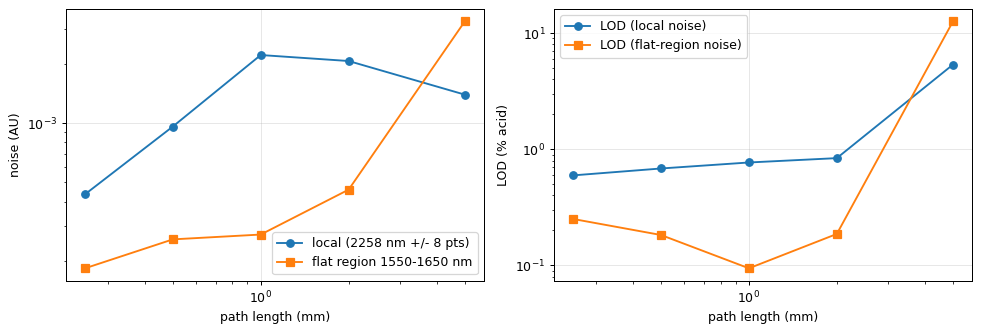

In [17]:
flat = (wl >= 1550) & (wl <= 1650)
print('平坦區 1550-1650 nm 共 %d 個點' % flat.sum())

NOISE_FLAT, LOD_FLAT = {}, {}
for p in PATHS:
    r_flat = (spec[p] - SMOOTH[p])[:, flat]
    assert not np.isnan(r_flat).any()
    NOISE_FLAT[p] = pop_std(r_flat)
    for k in BANDS:
        LOD_FLAT[(p, k)] = 3 * NOISE_FLAT[p] * np.sqrt(np.sum(c2**2)) / abs(CAL[(p, k)]['slope'])

print(pd.DataFrame({'path_mm': PATHS,
                    'noise_flat_AU': [NOISE_FLAT[p] for p in PATHS],
                    'noise_local_2258_AU': [NOISE_LOC[(p, '2258')] for p in PATHS],
                    'LOD_flat_2258_%': [LOD_FLAT[(p, '2258')] for p in PATHS],
                    'LOD_local_2258_%': [LOD_LOC[(p, '2258')] for p in PATHS]}).to_string(
    index=False, float_format=lambda v: '%.4g' % v))

print('\n報告的平坦區雜訊：0.25 mm 0.00018、0.5 mm 0.00026、1 mm 0.00027 AU')
print('本程式算出來：      0.25 mm %.5f、0.5 mm %.5f、1 mm %.5f AU' % (NOISE_FLAT[0.25], NOISE_FLAT[0.5], NOISE_FLAT[1]))
print('2258 nm 帶 LOD(0.25 mm) / LOD(1 mm) = %.2f  (報告：1 mm 約為 0.25 mm 的 1/2.6)' %
      (LOD_FLAT[(0.25, '2258')] / LOD_FLAT[(1, '2258')]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(PATHS, [NOISE_LOC[(p, '2258')] for p in PATHS], 'o-', label='local (2258 nm +/- 8 pts)')
ax[0].semilogy(PATHS, [NOISE_FLAT[p] for p in PATHS], 's-', label='flat region 1550-1650 nm')
ax[0].set_xscale('log'); ax[0].set_xlabel('path length (mm)'); ax[0].set_ylabel('noise (AU)'); ax[0].legend()
ax[1].semilogy(PATHS, [LOD_LOC[(p, '2258')] for p in PATHS], 'o-', label='LOD (local noise)')
ax[1].semilogy(PATHS, [LOD_FLAT[(p, '2258')] for p in PATHS], 's-', label='LOD (flat-region noise)')
ax[1].set_xscale('log'); ax[1].set_xlabel('path length (mm)'); ax[1].set_ylabel('LOD (% acid)'); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**結論**：平坦區雜訊幾乎不隨光徑改變（0.00018 → 0.00027 AU），而斜率隨光徑增加，
所以 1 mm 的 LOD 約只有 0.25 mm 的 1/2.6。局部雜訊會讓你得到「短光徑 LOD 較低」的**錯誤**結論。

> 2 mm 以上的平坦區雜訊會變大（在飽和邊緣），而 5 mm 的斜率本身不可靠，所以 LOD 的比較只在未飽和的光徑才有意義。

### 動手改改看（第 5 節）
1. 把 `SMOOTH_WIN` 改成 9 或 5，平坦區雜訊變大還是變小？為什麼？（提示：平滑得越少，殘差越小。）
2. 把平坦區改成 1900–2050 nm（水的強吸收帶、1 mm 已接近飽和），雜訊與 LOD 會怎樣？
3. 用 `replicate == 2` 的 0.25 mm 水光譜與 `replicate == 1` 的水光譜相減，計算 `pop_std(a - b)`。
   這代表「填樣再現性」的下限；它和平坦區雜訊（0.00018 AU）相比是大還是小？
4. 局部雜訊的範圍從 ±8 點改成 ±3 點，LOD 會怎麼變？

## 6. 基礎⑤：留一交叉驗證 (LOOCV) 與 RMSECV

R² 只說明模型對「用來建模的那些點」擬合得多好，**不代表對新樣品預測得好**。
**留一交叉驗證**：每次留下 1 個點，用其餘點建立校正線，再預測被留下那點的濃度：

1. 用其他 3 點擬合：y = 截距 + 斜率 · x。
2. 把被留下點的 y 代回，反推濃度：x̂ = (y − 截距) / 斜率。
3. 誤差 e = x − x̂。
4. 重複 4 次，RMSECV = √(平均 e²)，單位 = % 酸度。

先用玩具例子（沿用第 3 節的 4 點）：

In [18]:
def loocv(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    errs = []
    for j in range(len(x)):
        keep = np.arange(len(x)) != j                        # 留下第 j 點
        s, b0, _ = fit_line(x[keep], y[keep])                # 用另外的點擬合
        x_hat = (y[j] - b0) / s                              # 預測被留下點的濃度
        errs.append(x[j] - x_hat)
    errs = np.array(errs)
    return float(np.sqrt(np.mean(errs**2))), errs

rmsecv_t, e_t = loocv(xt, yt)
print('玩具例子：每次的誤差 =', np.round(e_t, 4), ' RMSECV = %.4f' % rmsecv_t)

for p in PATHS:
    for k in BANDS:
        CAL[(p, k)]['rmsecv'] = loocv(conc, CAL[(p, k)]['sig'])[0]
print(pd.DataFrame([{'path_mm': p, 'band_nm': k, 'R2': CAL[(p, k)]['r2'], 'RMSECV_%': CAL[(p, k)]['rmsecv']}
                    for k in BANDS for p in PATHS]).to_string(index=False, float_format=lambda v: '%.4g' % v))

玩具例子：每次的誤差 = [-0.0171  0.0967 -0.1723  0.1789]  RMSECV = 0.1335
 path_mm band_nm     R2  RMSECV_%
    0.25    2258 0.9589     1.076
     0.5    2258 0.8533     3.344
       1    2258 0.9342     2.182
       2    2258 0.9498     1.224
       5    2258  0.323     17.16
    0.25    1670 0.8548      3.72
     0.5    1670 0.7873     4.172
       1    1670 0.9448     1.945
       2    1670 0.8508     3.493
       5    1670  0.999    0.1578


**觀察**：0.5 mm 的 RMSECV 最大（3.3%）；它的 3.32% 那條光譜有基線偏移。
2 mm 的 R²、RMSECV 看起來不差（0.95、1.2%），但它已經飽和，**這是 n = 4 的假象**，不能採信。
5 mm 的 RMSECV 高達 17%，校正線幾乎沒有預測能力。
RMSECV 與 R² 只是**輔助參考**，不是選光徑的主要依據。

### 動手改改看（第 6 節）
1. 只留 n = 3 點（刪掉某一個濃度）再做 LOOCV，還能做嗎？誤差有什麼變化？
2. 把玩具例子的 `yt[3]` 從 7.8 改成 9.0（製造一個離群點），RMSECV 與 R² 哪一個反應比較大？
3. 為什麼 n = 4 的交叉驗證結果本身就很不穩定？（提示：每次只剩 3 個點擬合。）

## 7. 決策規則

把前面的檢查合在一起：

> **在靈敏度仍與光徑成正比（Beer–Lambert 成立）的範圍內，取最長的光徑。**

具體化：某光徑通過檢查 = （2258 nm 帶靈敏度比 / 理想值）與 1 的差距 ≤ `RATIO_TOL`，**且** 特徵帶附近最大吸光度 < `A_SAT`（未飽和）。
通過的光徑中取最長者。

In [19]:
def band_amax(p, k):
    i = IDX[k]; hh = SG_WIN // 2
    return float(spec[p][:, max(i - hh, 0): i + hh + 1].max())   # 特徵帶 +/- 半個視窗內，4 條光譜的最大 A

dec = []
for p in PATHS:
    ratio = CAL[(p, '2258')]['slope'] / CAL[(0.25, '2258')]['slope']
    rel = ratio / (p / 0.25)
    ok_bl = abs(rel - 1) <= RATIO_TOL
    ok_sat = band_amax(p, '2258') < A_SAT
    dec.append({'path_mm': p, 'ratio': ratio, 'ideal': p / 0.25, 'ratio/ideal': rel,
                'Amax_2258': band_amax(p, '2258'), 'BeerLambert_ok': ok_bl, 'unsaturated': ok_sat,
                'pass': ok_bl and ok_sat})
dec = pd.DataFrame(dec)
print(dec.to_string(index=False, float_format=lambda v: '%.3f' % v))
SELECTED = max(dec.loc[dec['pass'], 'path_mm'])
print('\n選擇的光徑 = %g mm' % SELECTED)

 path_mm  ratio  ideal  ratio/ideal  Amax_2258  BeerLambert_ok  unsaturated  pass
   0.250  1.000  1.000        1.000      0.588            True         True  True
   0.500  1.927  2.000        0.964      0.883            True         True  True
   1.000  3.946  4.000        0.987      1.575            True         True  True
   2.000  3.375  8.000        0.422      2.225           False        False False
   5.000 -0.356 20.000       -0.018      2.245           False        False False

選擇的光徑 = 1 mm


In [20]:
def usable_segments(S, thr):
    # 4 條光譜在該波長都 < thr 的「連續區段」（至少 2 點）
    ok = S.max(axis=0) < thr
    segs, i = [], 0
    while i < n_wl:
        if ok[i]:
            j = i
            while j + 1 < n_wl and ok[j + 1]:
                j += 1
            if j > i:
                segs.append('%.0f-%.0f' % (wl[i], wl[j]))
            i = j + 1
        else:
            i += 1
    return segs

USABLE = {p: usable_segments(spec[p], A_LIM) for p in PATHS}
print('各光徑可用波段（4 條光譜皆 A < %g）：' % A_LIM)
for p in PATHS:
    print('  %5g mm: %s' % (p, ', '.join(USABLE[p]) if USABLE[p] else '(無)'))

各光徑可用波段（4 條光譜皆 A < 1.5）：
   0.25 mm: 1347-2542
    0.5 mm: 1347-1889, 2011-2435
      1 mm: 1347-1413, 1480-1871, 2116-2284
      2 mm: 1347-1389, 1554-1845
      5 mm: 1347-1351


**結論**：選 **1 mm**。1 mm 的可用波段為 1480–1871 nm 與 2116–2284 nm
（程式還會多列出 1347–1413 nm，那是光譜最短波長端、被 1450 nm 水帶隔開的孤立小段，報告沒有採用），2258 nm 與 1670 nm 兩個醋酸帶都落在裡面；
1890–2100 nm（水的 1940 nm 帶）與 2300 nm 以上已飽和，必須排除在模型之外。
若將來樣品濃度更高或需要 1940 nm 水帶，改用 0.5 mm（可用 1347–1889、2011–2435 nm）。

### 動手改改看（第 7 節）
1. 把 `RATIO_TOL` 改成 0.02，會選到哪一個光徑？改成 0.6 呢？規則對這個參數敏感嗎？
2. 把 `A_LIM` 改成 2.0，1 mm 的可用波段變成什麼？（記得重跑參數格與本節。）
3. 這個規則只用了 2258 nm 帶。改用 1670 nm 帶判斷，結論會一樣嗎？為什麼？

## 8. 延伸：改用其他參考值

Atago 是用導電度換算酸度，在高濃度可能讀低。另一組學生做了手動滴定：標示 3/5/10% 的三瓶分別為 **2.28 / 4.40 / 11.39 %**。
用 1 mm 的兩個特徵帶，比較對不同參考值的線性（R²）：

                    reference  2258_R2  1670_R2
     Atago (0/3.32/4.87/7.45)    0.934    0.945
             label (0/3/5/10)    0.996    0.998
titration (0/2.28/4.40/11.39)    0.990    0.987


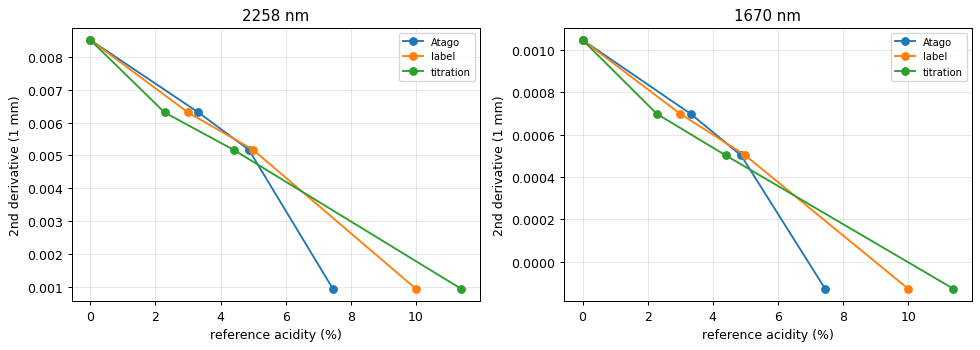

In [21]:
REFS = {
    'Atago (0/3.32/4.87/7.45)':   [0, 3.32, 4.87, 7.45],
    'label (0/3/5/10)':           [0, 3, 5, 10],
    'titration (0/2.28/4.40/11.39)': [0, 2.28, 4.40, 11.39],
}
R2_EXT = {}
for name, xr in REFS.items():
    for k in BANDS:
        R2_EXT[(name, k)] = fit_line(xr, CAL[(1, k)]['sig'])[2]

print(pd.DataFrame([{'reference': name, '2258_R2': R2_EXT[(name, '2258')], '1670_R2': R2_EXT[(name, '1670')]}
                    for name in REFS]).to_string(index=False, float_format=lambda v: '%.3f' % v))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, k in enumerate(BANDS):
    for name, xr in REFS.items():
        ax[c].plot(xr, CAL[(1, k)]['sig'], 'o-', label=name.split(' ')[0])
    ax[c].set_xlabel('reference acidity (%)'); ax[c].set_ylabel('2nd derivative (1 mm)')
    ax[c].set_title('%s nm' % k); ax[c].legend(fontsize=8); ax[c].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**解讀**：改用標示值或滴定值，1 mm 的 R² 從約 0.93 升到 0.99 以上，兩個獨立的醋酸帶都一致。
表示先前「7.45% 偏高」比較可能是 Atago 把 10% 的瓶子讀低了，不是 NIR 的問題。
（n = 4、每瓶只填一次樣，R² 的差異只能當「一致的跡象」，不能當統計上的證明。）

### 動手改改看（第 8 節）
1. 把 0.25 mm 與 2 mm 的 R² 也用標示值算一次。短光徑的改善與 1 mm 一樣明顯嗎？
2. 滴定值與 Atago 的比值（0.76 → 1.07 → 1.66）不是常數，這為什麼排除了「NaOH 力價誤差」的解釋？
3. 如果要建立真正的校正，你會怎麼改實驗設計？（提示：同一瓶醋稀釋、每個濃度重複填樣。）

## 9. 自我驗證

下面把你算出來的結果與答案鍵（原報告與 `pathlength_metrics.csv`）逐項比對：
比值與 R² 容許 ±0.01，其他容許相對誤差 2%。

> 如果你改過上面的參數（`A_LIM`、`SG_WIN` 等），許多項目 FAIL 是正常的；把參數改回預設、整本重跑即可。

In [22]:
checks = []
def chk(name, got, key, kind):
    # kind: 'abs' -> 絕對誤差 <= 0.01；'rel' -> 相對誤差 <= 2%；'tol' -> 自訂絕對誤差（由 key 的 (值, 容差) 給）
    if kind == 'abs':
        ok = abs(got - key) <= 0.01 + 1e-12
    elif kind == 'rel':
        ok = abs(got - key) <= 0.02 * abs(key)
    else:
        key, tol = key
        ok = abs(got - key) <= tol
        key = key
    checks.append((ok, name, got, key))

# ---- 2258 nm 帶答案鍵 ----
K2258 = {  # path: (A<1.5, A<2.0, Amax, slope, ratio, R2, RMSECV, noise_A, LOD)
    0.25: (1.000, 1.000, 0.5877, -2.497e-4, 1.00,  0.9589, 1.076, 4.353e-4, 0.5961),
    0.5:  (0.8662, 0.9648, 0.8827, -4.811e-4, 1.93, 0.8533, 3.344, 9.618e-4, 0.6835),
    1:    (0.6197, 0.8099, 1.575, -9.852e-4, 3.95,  0.9342, 2.182, 2.218e-3, 0.7698),
    2:    (0.3662, 0.4437, 2.225, -8.427e-4, 3.38,  0.9498, 1.223, 2.068e-3, 0.8391),
    5:    (0.01408, 0.169, 2.245, 8.893e-5, -0.36,  0.3229, 17.16, 1.396e-3, 5.367),
}
# ---- 1670 nm 帶（取自 pathlength_metrics.csv）----
K1670 = {  # path: (Amax, slope, R2, RMSECV, noise_A, LOD)
    0.25: (0.4232, -2.859e-05, 0.855,  3.712,  2.997e-4, 3.584),
    0.5:  (0.4706, -7.549e-05, 0.7873, 4.173,  4.357e-4, 1.973),
    1:    (0.7422, -1.535e-04, 0.9448, 1.945,  5.066e-4, 1.128),
    2:    (1.073,  -3.010e-04, 0.8508, 3.493,  8.118e-4, 0.9219),
    5:    (1.909,  -4.342e-04, 0.999,  0.1577, 1.917e-3, 1.509),
}
for p in PATHS:
    f15, f20, am, sl, rt, r2, rm, nz, lod = K2258[p]
    t = '2258 %g mm ' % p
    chk(t + 'frac A<1.5', frac_below(spec[p], 1.5), f15, 'abs')
    chk(t + 'frac A<2.0', frac_below(spec[p], 2.0), f20, 'abs')
    chk(t + 'Amax(band)', band_amax(p, '2258'), am, 'rel')
    chk(t + 'slope',      CAL[(p, '2258')]['slope'], sl, 'rel')
    chk(t + 'ratio',      CAL[(p, '2258')]['slope'] / CAL[(0.25, '2258')]['slope'], rt, 'abs')
    chk(t + 'R2',         CAL[(p, '2258')]['r2'], r2, 'abs')
    chk(t + 'RMSECV%',    CAL[(p, '2258')]['rmsecv'], rm, 'rel')
    chk(t + 'noise_A',    NOISE_LOC[(p, '2258')], nz, 'rel')
    chk(t + 'LOD%',       LOD_LOC[(p, '2258')], lod, 'rel')
    am, sl, r2, rm, nz, lod = K1670[p]
    t = '1670 %g mm ' % p
    chk(t + 'Amax(band)', band_amax(p, '1670'), am, 'rel')
    chk(t + 'slope',      CAL[(p, '1670')]['slope'], sl, 'rel')
    chk(t + 'R2',         CAL[(p, '1670')]['r2'], r2, 'abs')
    chk(t + 'RMSECV%',    CAL[(p, '1670')]['rmsecv'], rm, 'rel')
    chk(t + 'noise_A',    NOISE_LOC[(p, '1670')], nz, 'rel')
    chk(t + 'LOD%',       LOD_LOC[(p, '1670')], lod, 'rel')

# ---- 手刻 SG 與 scipy ----
chk('hand-made SG vs scipy (max diff < 1e-9)', maxdiff, (0.0, 1e-9), 'tol')
# ---- 平坦區雜訊（報告只給 2 位有效數字，容許 +/-0.000006 AU）----
for p, key in [(0.25, 0.00018), (0.5, 0.00026), (1, 0.00027)]:
    chk('flat-region noise %g mm' % p, NOISE_FLAT[p], (key, 6e-6), 'tol')
chk('LOD ratio 0.25mm/1mm (2258, flat noise)', LOD_FLAT[(0.25, '2258')] / LOD_FLAT[(1, '2258')], (2.6, 0.1), 'tol')
# ---- 可用波段 ----
# 1 mm 的程式輸出多一段 1347-1413（光譜最短波長端的孤立小段），報告沒有列入；所以用「答案鍵的區段都出現」來比對
chk('usable bands 1 mm (key segs present)',   float(all(s in USABLE[1] for s in ['1480-1871', '2116-2284'])), (1.0, 0), 'tol')
chk('usable bands 0.5 mm (key segs present)', float(all(s in USABLE[0.5] for s in ['1347-1889', '2011-2435'])), (1.0, 0), 'tol')
# ---- 決策 ----
chk('selected path = 1 mm', float(SELECTED), (1.0, 0), 'tol')
# ---- 延伸 ----
chk('ext 2258 label R2',     R2_EXT[('label (0/3/5/10)', '2258')], 0.996, 'abs')
chk('ext 1670 label R2',     R2_EXT[('label (0/3/5/10)', '1670')], 0.998, 'abs')
chk('ext 2258 titration R2', R2_EXT[('titration (0/2.28/4.40/11.39)', '2258')], 0.990, 'abs')
chk('ext 1670 titration R2', R2_EXT[('titration (0/2.28/4.40/11.39)', '1670')], 0.987, 'abs')

print('%-6s | %-44s | %14s | %14s' % ('result', 'item', 'yours', 'key'))
print('-' * 88)
for ok, name, got, key in checks:
    print('%-6s | %-44s | %14.6g | %14.6g' % ('PASS' if ok else 'FAIL', name, got, key))
n_pass = sum(1 for c in checks if c[0])
print('-' * 88)
print('TOTAL: %d / %d PASS' % (n_pass, len(checks)))

result | item                                         |          yours |            key
----------------------------------------------------------------------------------------
PASS   | 2258 0.25 mm frac A<1.5                      |              1 |              1
PASS   | 2258 0.25 mm frac A<2.0                      |              1 |              1
PASS   | 2258 0.25 mm Amax(band)                      |       0.587734 |         0.5877
PASS   | 2258 0.25 mm slope                           |   -0.000249668 |     -0.0002497
PASS   | 2258 0.25 mm ratio                           |              1 |              1
PASS   | 2258 0.25 mm R2                              |        0.95892 |         0.9589
PASS   | 2258 0.25 mm RMSECV%                         |        1.07626 |          1.076
PASS   | 2258 0.25 mm noise_A                         |    0.000435303 |      0.0004353
PASS   | 2258 0.25 mm LOD%                            |       0.596081 |         0.5961
PASS   | 1670 0.25 mm Amax(band

### 總結
1. **看飽和**：2 mm 以上在 A ≈ 2.2–2.4 出現平台，Beer–Lambert 失效。
2. **二階導數**消除基線偏移與斜率；手刻 SG = 視窗內擬合二次式取 2a₂。
3. **斜率比**對照理想值 p / 0.25，判斷是否仍符合 Beer–Lambert。
4. **LOD** 的雜訊要在平坦未飽和區估算，否則會把譜形誤當雜訊。
5. **RMSECV、R²** 只是輔助（n = 4 很不穩）。
6. 決策：**在 Beer–Lambert 成立的範圍內取最長光徑 → 1 mm**。